# 03 · Online SLAM

Full Graph SLAM keeps every pose in the state. Ω grows as `2(N + L)` per side, so memory grows as N² and a dense solve as N³. Many applications only need the *current* pose and the map. **Online SLAM** keeps exactly that: a state of size `2 + 2L`, independent of how long the robot has been driving.

**How.** At each step:

1. Add the measurements taken at the current pose, as usual.
2. Add a new pose and link it to the current one with the motion constraint. The state is now `[old pose, new pose, landmarks]`.
3. Remove the old pose by marginalization (Schur complement). With `Ω_old` the old pose's 2 × 2 block, `A` its coupling to everything else, and `B` the rest:

```
Ω' = B − Aᵀ Ω_old⁻¹ A
ξ' = ξ_B − Aᵀ Ω_old⁻¹ ξ_old
```

For a linear system like this one, marginalization is exact: online SLAM must return *the same* final pose and landmarks as full SLAM, up to rounding. Earlier poses are not recovered, though; once marginalized, they are gone.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable
ASSETS = Path.cwd().parent / "assets"

import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np

import slam
import viz
import world
from data import udacity_test_cases as U

## Verification: online == full

In [2]:
def compare(name, data, num_landmarks, **kwargs):
    P, L = slam.slam_observed(data, num_landmarks, **kwargs)
    p, l = slam.online_slam(data, num_landmarks, **kwargs)
    unseen = int(np.isnan(L).any(axis=1).sum())
    print("%-22s N=%4d  max |pose diff| %.1e   max |landmark diff| %.1e   (unseen landmarks: %d)"
          % (name, len(P), np.abs(p - P[-1]).max(), np.nanmax(np.abs(l - L)), unseen))

udacity = dict(world_size=100.0, motion_noise=2.0, measurement_noise=2.0)
compare("Udacity test case 1", U.TEST_DATA_1, 5, **udacity)
compare("Udacity test case 2", U.TEST_DATA_2, 5, **udacity)
for seed in (0, 1, 2):
    sim = world.simulate_random(N=200, num_landmarks=8, seed=seed)
    compare("random world, seed %d" % seed, sim.data, sim.num_landmarks, **sim.slam_args())
loop = world.simulate_waypoints(*world.loop_world(spacing=20.0, laps=1.25), measurement_range=12.0,
                                motion_noise=3.0, measurement_noise=1.0, seed=6)
compare("loop world, seed 6", loop.data, loop.num_landmarks, **loop.slam_args())

Udacity test case 1    N=  20  max |pose diff| 1.6e-13   max |landmark diff| 2.0e-13   (unseen landmarks: 0)
Udacity test case 2    N=  20  max |pose diff| 2.9e-13   max |landmark diff| 3.1e-13   (unseen landmarks: 0)
random world, seed 0   N= 200  max |pose diff| 6.5e-12   max |landmark diff| 6.6e-12   (unseen landmarks: 0)
random world, seed 1   N= 200  max |pose diff| 4.7e-12   max |landmark diff| 4.7e-12   (unseen landmarks: 0)
random world, seed 2   N= 200  max |pose diff| 5.4e-12   max |landmark diff| 5.4e-12   (unseen landmarks: 0)
loop world, seed 6     N=  70  max |pose diff| 8.3e-13   max |landmark diff| 2.0e-12   (unseen landmarks: 1)


The differences are around 1e-13 to 1e-11, which is floating-point rounding: the two methods agree. The same check runs in `tests/test_slam.py` on every push.

## What marginalization does to Ω

Removing a pose connects everything it was connected to. In full SLAM, landmarks are only linked through poses. In online SLAM, every landmark that was seen from a marginalized pose becomes directly linked to the others, so the landmark block fills in. Ω gets much smaller, but it stops being sparse.

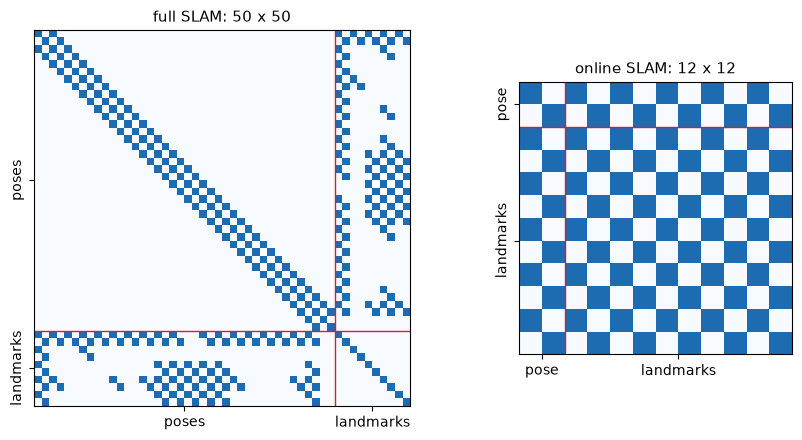

In [3]:
sim = world.simulate_random(N=20, num_landmarks=5, seed=0)
omega_full, _ = slam.build_system(sim.data, sim.N, sim.num_landmarks, **sim.slam_args())
_, _, (omega_online, _) = slam.online_slam(sim.data, sim.num_landmarks, return_system=True, **sim.slam_args())

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 4.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
viz.plot_omega(a, omega_full, sim.N, sim.num_landmarks, title="full SLAM: %d x %d" % omega_full.shape)
viz.plot_omega(b, omega_online, 1, sim.num_landmarks, title="online SLAM: %d x %d" % omega_online.shape)
b.set_xticklabels(["pose", "landmarks"]); b.set_yticklabels(["pose", "landmarks"], rotation=90, va="center")
fig.tight_layout()
plt.show()

## Time and memory

Random world with 5 landmarks, N from 20 to 2000 poses. Time is the best of 3 runs, building the system plus solving it (a single run for full SLAM at N ≥ 1000). Memory is the peak traced by `tracemalloc` during one call, which for full SLAM is dominated by the dense Ω (`8 · (2(N+L))²` bytes).

In [4]:
def bench(fn, reps):
    best = min(_timed(fn) for _ in range(reps))
    tracemalloc.start()
    fn()
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return best, peak

def _timed(fn):
    t = time.perf_counter()
    fn()
    return time.perf_counter() - t

Ns = [20, 100, 500, 1000, 2000]
rows = []
for N in Ns:
    sim = world.simulate_random(N=N, num_landmarks=5, seed=0)
    kw = sim.slam_args()
    t_full, m_full = bench(lambda: slam.slam(sim.data, sim.N, sim.num_landmarks, **kw), 3 if N < 1000 else 1)
    t_online, m_online = bench(lambda: slam.online_slam(sim.data, sim.num_landmarks, **kw), 3)
    rows.append((N, t_full, t_online, m_full, m_online))
    print("N=%5d  full %8.4f s %9.2f MB   online %8.4f s %7.3f MB" % (N, t_full, m_full / 1e6, t_online, m_online / 1e6))
rows = np.array(rows)

N=   20  full   0.0003 s      0.02 MB   online   0.0006 s   0.012 MB
N=  100  full   0.0014 s      0.36 MB   online   0.0025 s   0.012 MB


N=  500  full   0.0127 s      8.18 MB   online   0.0126 s   0.012 MB


N= 1000  full   0.0561 s     32.35 MB   online   0.0248 s   0.012 MB


N= 2000  full   0.2721 s    128.71 MB   online   0.0485 s   0.012 MB


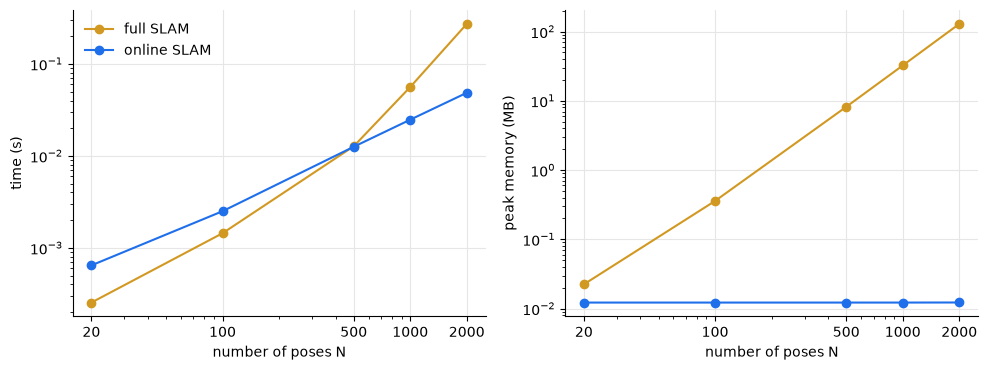

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col_full, col_online, label in ((a, 1, 2, "time (s)"), (b, 3, 4, "peak memory (MB)")):
    scale = 1 if col_full == 1 else 1e-6
    ax.loglog(rows[:, 0], rows[:, col_full] * scale, "o-", color=viz.DR, label="full SLAM")
    ax.loglog(rows[:, 0], rows[:, col_online] * scale, "o-", color=viz.EST, label="online SLAM")
    ax.set_xlabel("number of poses N")
    ax.set_ylabel(label)
    ax.set_xticks(Ns); ax.set_xticklabels([str(n) for n in Ns])
    ax.grid(True, which="major", color="#e6e6e6")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
a.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSETS / "online_vs_full.png", dpi=120)
plt.show()

The measured times are from an Apple M3 Pro and will vary between runs and machines; the trends are what matter.

- **Memory.** Full SLAM grows with N², from 0.02 MB at N = 20 to about 129 MB at N = 2000. Online SLAM stays at about 12 KB, because its Ω is always 12 × 12 with 5 landmarks.
- **Time.** Online SLAM grows linearly, with a constant cost per step. Full SLAM grows faster than linearly because of the dense solve. Below a few hundred poses, the Python loop in online SLAM costs about as much as the whole dense solve, and full SLAM is as fast or faster. At N = 2000, online SLAM is about 6× faster.
- **What full SLAM keeps.** Full SLAM still has the whole trajectory, and with it the ability to correct past poses after a loop closure (notebook 04). With a sparse solver (for example `scipy.sparse.linalg.spsolve`, or a Cholesky factorization that exploits the band structure), full SLAM would scale close to linearly as well, because its Ω stays sparse.